# Replicate Signature Similarity Violins

This notebook reads the precomputed replicate signature outputs and plots per-dataset violins and heatmaps for within-dataset logFC Spearman correlation. Summary tables below each violin report means/medians for observed scores, centroid baselines, and peer baselines.

Each distribution uses all of its available scores independently. Summary and heatmap deltas average the precomputed paired observed-minus-baseline differences.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

def find_repo_root(start=None) -> Path:
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "results").exists() and (candidate / "notebooks").exists():
            return candidate
    raise FileNotFoundError("Could not locate the repository root from the current working directory.")


REPO_ROOT = find_repo_root()
RESULTS_DIR = REPO_ROOT / "results" / "replicate_signature_similarity_sep_rep"
DATASET_ORDER = [
    "cigs_mce",
    "cigs_tcm",
    "dilimap_train_val",
    "gdpx2",
    
    
    "l1000_phase1",
    "l1000_phase2",
    
    "novartis_batch_2500",
    "op3",
    "sciplex",
    "tahoe",
    "vcpi_0001",
    "vcpi_0002",
    
    
    
]
PRETTY_LABELS = {
    "l1000_phase1": "L1000 Phase I",
    "l1000_phase2": "L1000 Phase II",
    "tahoe": "Tahoe-100M",
    "cigs_mce": "CIGS-MCE",
    "novartis_batch_2500": "Novartis/DRUG-seq U2OS",
    "vcpi_0001": "VCPI-0001",
    "cigs_tcm": "CIGS-TCM",
    "vcpi_0002": "VCPI-0002",
    "gdpx2": "GDPx2",
    "sciplex": "sci-Plex",
    "dilimap_train_val": "DILImap",
    "op3": "OP3",
}
DATASET_ORDER_MAP = {dataset_name: idx for idx, dataset_name in enumerate(DATASET_ORDER)}

sns.set_theme(style="whitegrid", context="talk")


def pretty_label(dataset_name: str) -> str:
    return PRETTY_LABELS.get(str(dataset_name), str(dataset_name))


def dataset_names_in_order(frame: pd.DataFrame) -> list[str]:
    present = set(frame["dataset_name"].dropna().astype(str).unique().tolist())
    ordered = [dataset_name for dataset_name in DATASET_ORDER if dataset_name in present]
    ordered.extend(sorted(dataset_name for dataset_name in present if dataset_name not in DATASET_ORDER_MAP))
    return ordered


def dataset_label_order(frame: pd.DataFrame) -> list[str]:
    return [pretty_label(dataset_name) for dataset_name in dataset_names_in_order(frame)]


def sort_by_dataset_order(frame: pd.DataFrame) -> pd.DataFrame:
    sort_frame = frame.copy()
    sort_frame["_dataset_order"] = sort_frame["dataset_name"].astype(str).map(DATASET_ORDER_MAP).fillna(len(DATASET_ORDER))
    return (
        sort_frame.sort_values(["_dataset_order", "dataset_name"])
        .drop(columns="_dataset_order")
        .reset_index(drop=True)
    )


def validate_condition_metric_counts(condition_frame: pd.DataFrame, dataset_summary: pd.DataFrame, *, condition_summary_name: str) -> pd.DataFrame:
    missing_condition_columns = sorted({"dataset_name", "condition_key"} - set(condition_frame.columns))
    if missing_condition_columns:
        raise KeyError(f"Missing columns in {condition_summary_name}: {missing_condition_columns}")
    missing_dataset_columns = sorted({"dataset_name", "n_conditions"} - set(dataset_summary.columns))
    if missing_dataset_columns:
        raise KeyError(f"Missing columns in dataset summary: {missing_dataset_columns}")

    expected = dataset_summary[["dataset_name", "n_conditions"]].copy()
    expected["dataset_name"] = expected["dataset_name"].astype(str)
    expected["expected_n_conditions"] = pd.to_numeric(expected["n_conditions"], errors="raise").round().astype(int)
    expected = expected[["dataset_name", "expected_n_conditions"]]

    observed_source = condition_frame[["dataset_name"]].copy()
    observed_source["dataset_name"] = observed_source["dataset_name"].astype(str)
    observed = observed_source.groupby("dataset_name").size().rename("observed_n_conditions").reset_index()

    comparison = expected.merge(observed, on="dataset_name", how="outer")
    comparison[["expected_n_conditions", "observed_n_conditions"]] = (
        comparison[["expected_n_conditions", "observed_n_conditions"]].fillna(0).astype(int)
    )
    comparison = sort_by_dataset_order(comparison)
    mismatches = comparison.loc[comparison["expected_n_conditions"] != comparison["observed_n_conditions"]]
    if not mismatches.empty:
        raise ValueError(
            f"{condition_summary_name} does not match the merged dataset summary. "
            "This usually means one of the combined output files is stale.\n"
            + mismatches.to_string(index=False)
        )
    return comparison



def plot_summary_heatmap(
    summary: pd.DataFrame,
    *,
    title: str,
    value_label: str,
    pdf_name: str,
    vmin=None,
    vmax=None,
    show_colorbar: bool = True,
    show_dataset_labels: bool = True,
) -> pd.DataFrame:
    required_columns = {"dataset_name", "dataset_label", "observed_mean", "centroid_baseline_mean", "peer_baseline_mean", "delta_centroid", "delta_peer"}
    missing = sorted(required_columns - set(summary.columns))
    if missing:
        raise KeyError(f"Missing columns for heatmap {title!r}: {missing}")

    # Deltas are means of precomputed paired differences, as in the tables.
    summary_frame = summary.copy()

    summary_frame = sort_by_dataset_order(summary_frame)

    heatmap_frame = summary_frame[["dataset_label", 
                                   "observed_mean", 
                                   "centroid_baseline_mean", 
                                   "peer_baseline_mean", 
                                   "delta_centroid", 
                                   "delta_peer"]].rename(
        columns={
            "dataset_label": "Dataset",
            "observed_mean": "Observed",
            "centroid_baseline_mean": "Centroid baseline",
            "peer_baseline_mean": "Peer baseline",
            "delta_centroid": r'$\Delta$ centroid',
            "delta_peer": r'$\Delta$ peer',

        }
    ).set_index("Dataset")

    fig, ax = plt.subplots(figsize=(11.0, max(4.5, 1.0 * len(heatmap_frame))))
    sns.heatmap(
        heatmap_frame,
        annot=True,
        fmt=".3f",
        cmap="RdBu_r",
        center=0.0,
        vmin=vmin,
        vmax=vmax,
        linewidths=0.5,
        linecolor="white",
        cbar=show_colorbar,
        cbar_kws={"label": value_label} if show_colorbar else {},
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    if show_dataset_labels:
        ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
    else:
        ax.tick_params(axis="y", labelleft=False, length=0)
    fig.tight_layout()
    out_path = RESULTS_DIR / pdf_name
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"Saved heatmap to {out_path}")
    display(heatmap_frame)
    return heatmap_frame


In [2]:
def plot_violin_with_baseline(frame: pd.DataFrame, *, observed_col: str, baseline_col: str, peer_baseline_col: str, centroid_delta_col: str, peer_delta_col: str | None, title: str, ylabel: str, pdf_name: str) -> pd.DataFrame:
    column_map = {
        observed_col: "observed",
        baseline_col: "centroid baseline",
        centroid_delta_col: "delta_centroid",
    }
    if peer_baseline_col is not None:
        if peer_delta_col is None:
            raise ValueError("peer_delta_col is required when a peer baseline is supplied.")
        column_map[peer_baseline_col] = "peer baseline"
        column_map[peer_delta_col] = "delta_peer"
    required_columns = {"dataset_name", "condition_key", *column_map}
    missing = sorted(required_columns - set(frame.columns))
    if missing:
        raise KeyError(f"Missing columns for plot {title!r}: {missing}")
    plot_frame = frame[["dataset_name", "condition_key", *column_map]].copy()
    plot_frame = plot_frame.rename(columns=column_map)
    if peer_baseline_col is None:
        plot_frame["peer baseline"] = float("nan")
        plot_frame["delta_peer"] = float("nan")
    plot_frame["dataset_label"] = plot_frame["dataset_name"].map(pretty_label)
    # Retain all conditions; score availability is independent for each distribution.
    if not plot_frame[["observed", "centroid baseline", "peer baseline"]].notna().any().any():
        raise ValueError(f"No score values available for plot {title!r}.")
    observed_frame = plot_frame.loc[plot_frame["observed"].notna()].copy()
    observed_count_by_dataset = observed_frame.groupby("dataset_name")["condition_key"].nunique()

    order = dataset_label_order(plot_frame)
    fig_width = max(10.0, 1.35 * len(order) + 2.0)
    fig, ax = plt.subplots(figsize=(fig_width, 6.4))

    baseline_frame = plot_frame.loc[plot_frame["centroid baseline"].notna()].copy()
    peer_baseline_frame = plot_frame.loc[plot_frame["peer baseline"].notna()].copy()
    baseline_count_by_dataset = baseline_frame.groupby("dataset_name")["condition_key"].nunique() if not baseline_frame.empty else pd.Series(dtype=int)
    peer_baseline_count_by_dataset = peer_baseline_frame.groupby("dataset_name")["condition_key"].nunique() if not peer_baseline_frame.empty else pd.Series(dtype=int)
    
    
    observed_violin_frame = observed_frame[["dataset_name", "dataset_label", "condition_key", "observed"]].rename(columns={"observed": "score"})
    observed_violin_frame["score_type"] = "Cross replicate"
    baseline_violin_frame = baseline_frame[["dataset_name", "dataset_label", "condition_key", "centroid baseline"]].rename(columns={"centroid baseline": "score"})
    baseline_violin_frame["score_type"] = "Centroid Baseline"
    peer_baseline_violin_frame = peer_baseline_frame[["dataset_name", "dataset_label", "condition_key", "peer baseline"]].rename(columns={"peer baseline": "score"})
    peer_baseline_violin_frame["score_type"] = "Peer Baseline"
    violin_frame = pd.concat([observed_violin_frame, baseline_violin_frame, peer_baseline_violin_frame], ignore_index=True)
    hue_order = ["Cross replicate", "Centroid Baseline", "Peer Baseline"] if not (baseline_violin_frame.empty and peer_baseline_violin_frame.empty) else ["Cross replicate"]

    sns.violinplot(
        data=violin_frame,
        x="dataset_label",
        y="score",
        hue="score_type",
        order=order,
        hue_order=hue_order,
        inner=None,
        cut=0,
        linewidth=1.0,
        palette={"Cross replicate": "#dbe9f6", "Centroid Baseline": "#f4c7c3", "Peer Baseline": "#d9ead3"},
        #dodge=True,
        ax=ax,
    )

    summary = plot_frame.groupby(["dataset_name", "dataset_label"], as_index=False).agg(
        n_conditions=("condition_key", "nunique"),
        observed_mean=("observed", "mean"),
        observed_median=("observed", "median"),
        centroid_baseline_mean=("centroid baseline", "mean"),
        centroid_baseline_median=("centroid baseline", "median"),
        peer_baseline_mean=("peer baseline", "mean"),
        peer_baseline_median=("peer baseline", "median"),
        # These columns already average paired differences within each condition.
        delta_centroid=("delta_centroid", "mean"),
        delta_peer=("delta_peer", "mean"),
    )
    
    summary = sort_by_dataset_order(summary)
    summary["n_conditions_with_observed"] = summary["dataset_name"].map(observed_count_by_dataset).fillna(0).astype(int)
    summary["n_conditions_with_centroid_baseline"] = summary["dataset_name"].map(baseline_count_by_dataset).fillna(0).astype(int)
    summary["n_conditions_with_peer_baseline"] = summary["dataset_name"].map(peer_baseline_count_by_dataset).fillna(0).astype(int)
    if ax.get_legend() is not None:
        ax.legend(title="", loc="lower right", frameon=True)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=35)
    sns.despine(ax=ax)
    fig.tight_layout()
    out_path = RESULTS_DIR / pdf_name
    fig.savefig(out_path, bbox_inches="tight")
    plt.show()
    print(f"Saved plot to {out_path}")
    zero_baseline_c = summary.loc[summary["n_conditions_with_centroid_baseline"] == 0, "dataset_label"].tolist()
    zero_baseline_p = summary.loc[summary["n_conditions_with_peer_baseline"] == 0, "dataset_label"].tolist()
    if zero_baseline_c:
        print("No baseline-scored conditions in:", ", ".join(zero_baseline_c))
    if zero_baseline_p:
        print("No baseline-scored conditions in:", ", ".join(zero_baseline_p))
    display(summary)
    return summary


In [3]:
import json

condition_metric_summary = pd.read_csv(RESULTS_DIR / 'condition_metric_summary.tsv', sep='	')

print(
    f"Loaded {len(condition_metric_summary):,} condition rows across "
    f"{condition_metric_summary['dataset_name'].nunique():,} datasets from {RESULTS_DIR}."
)

condition_metric_summary.head()

Loaded 84,315 condition rows across 12 datasets from /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep.


,dataset_name,cell_type,pubchem_cid,time_key,dose_key,condition_key,perturbagen_display,n_replicates,n_replicate_pairs,n_total_possible_replicate_pairs,...,n_valid_peer_cosine_t_pairs,mean_replicate_deg_t_spearman_sym_p05,mean_baseline_pair_deg_t_spearman_sym_p05,mean_delta_vs_baseline_pair_deg_t_spearman_sym_p05,mean_delta_vs_peer_baseline_deg_t_spearman_sym_p05,mean_peer_baseline_deg_t_spearman_sym_p05,mean_peer_baseline_deg_t_spearman_sym_sd_p05,mean_peer_baseline_deg_t_spearman_sym_fraction_below_observed_p05,mean_peer_baseline_deg_t_spearman_sym_corrected_percentile_p05,n_valid_replicate_deg_t_spearman_sym_p05_pairs
0,dilimap_train_val,CL_0000182,444,24,3.703704,CL_0000182|444|24|3.7037037037,Bupropion,2,1,1,...,1,0.350029,0.370707,-0.020678,0.255966,0.094063,0.183241,0.908333,0.908714,1
1,dilimap_train_val,CL_0000182,444,24,11.000000,CL_0000182|444|24|11,Bupropion,2,1,1,...,1,0.362033,0.431154,-0.069121,0.281880,0.080153,0.271497,0.812749,0.813492,1
2,dilimap_train_val,CL_0000182,444,24,33.000000,CL_0000182|444|24|33,Bupropion,2,1,1,...,1,0.287213,0.360889,-0.073676,0.229352,0.057861,0.330341,0.740000,0.741036,1
3,dilimap_train_val,CL_0000182,444,24,100.000000,CL_0000182|444|24|100,Bupropion,3,3,3,...,3,0.472756,0.386294,0.086462,0.482242,-0.009486,0.349823,0.877604,0.878080,3
4,dilimap_train_val,CL_0000182,1775,24,37.000000,CL_0000182|1775|24|37,Phenytoin,6,6,15,...,6,0.245101,0.461873,-0.216772,0.129656,0.115445,0.145483,0.782552,0.783398,6


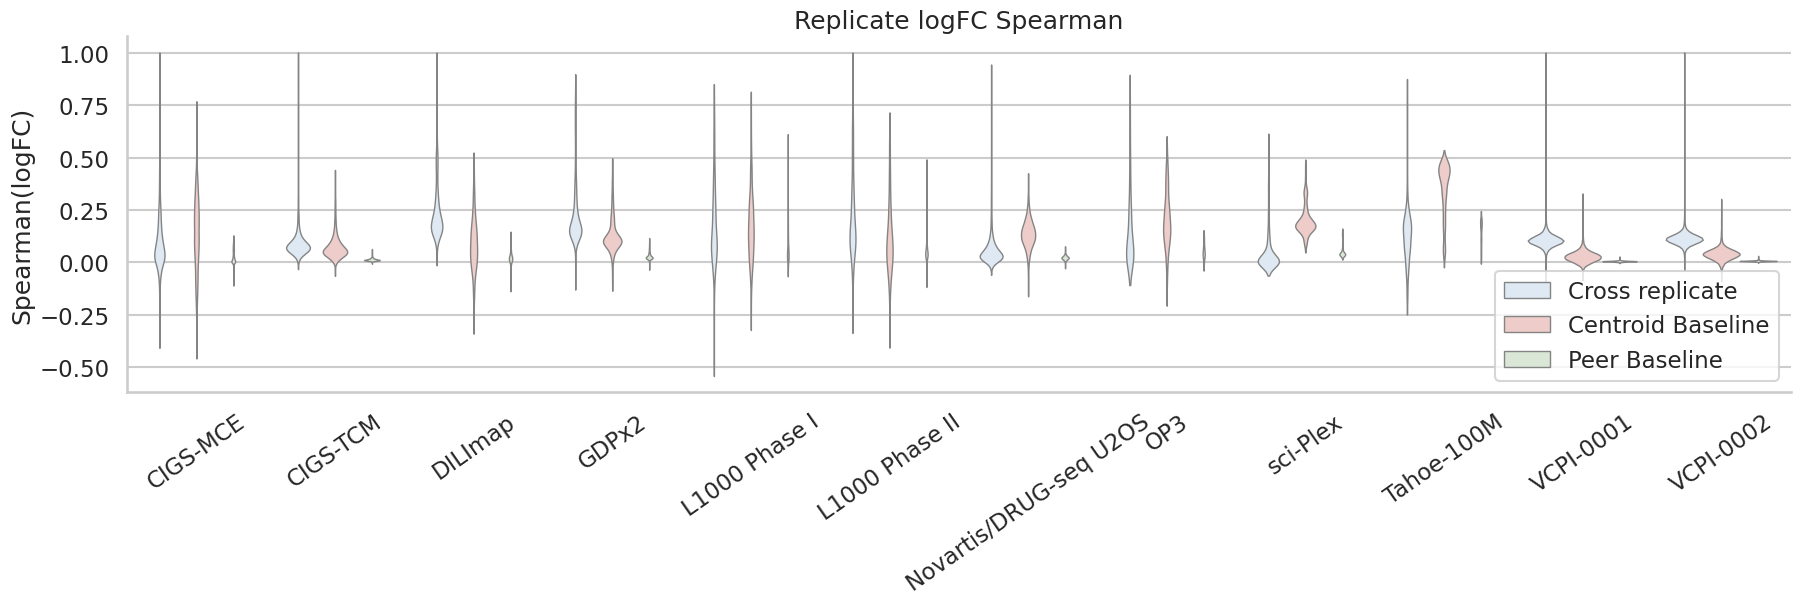

Saved plot to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_signature_logfc_violin.pdf


,dataset_name,dataset_label,n_conditions,observed_mean,observed_median,centroid_baseline_mean,centroid_baseline_median,peer_baseline_mean,peer_baseline_median,delta_centroid,delta_peer,n_conditions_with_observed,n_conditions_with_centroid_baseline,n_conditions_with_peer_baseline
0,cigs_mce,CIGS-MCE,21426,0.097999,0.066166,0.139760,0.147146,0.031314,0.019596,-0.041761,0.066685,21426,21426,21426
1,cigs_tcm,CIGS-TCM,7020,0.102538,0.078251,0.075854,0.061684,0.014036,0.012609,0.026684,0.088501,7020,7020,7020
2,dilimap_train_val,DILImap,1184,0.242160,0.198273,0.089059,0.080174,0.023964,0.021127,0.153157,0.218252,1184,1176,1176
3,gdpx2,GDPx2,2064,0.242817,0.173618,0.132793,0.109674,0.031076,0.025800,0.110024,0.211741,2064,2064,2064
4,l1000_phase1,L1000 Phase I,2517,0.187725,0.137974,0.174041,0.159699,0.068406,0.049567,0.012617,0.118252,2517,2437,2437
5,l1000_phase2,L1000 Phase II,2729,0.223118,0.168597,0.120835,0.089222,0.058429,0.046400,0.101940,0.164347,2729,2726,2726
6,novartis_batch_2500,Novartis/DRUG-seq U2OS,15276,0.071825,0.041633,0.136146,0.135410,0.023313,0.022894,-0.064321,0.048512,15276,15276,15276
7,op3,OP3,541,0.151550,0.093585,0.206908,0.186769,0.054051,0.048547,-0.055358,0.097499,541,541,541
8,sciplex,sci-Plex,2224,0.049556,0.014606,0.201016,0.183105,0.050122,0.041096,-0.151460,-0.000566,2224,2224,2224
9,tahoe,Tahoe-100M,7226,0.124576,0.130953,0.347681,0.394491,0.142618,0.161752,-0.223104,-0.018041,7226,7226,7226


In [4]:
signature_summary = plot_violin_with_baseline(
    condition_metric_summary,
    observed_col='mean_replicate_spearman_logfc',
    baseline_col='mean_replicate_baseline_spearman_logfc',
    peer_baseline_col = 'mean_peer_baseline_spearman_logfc',
    centroid_delta_col='mean_replicate_minus_baseline_spearman_logfc',
    peer_delta_col='mean_replicate_minus_peer_baseline_spearman_logfc',
    title='Replicate logFC Spearman',
    ylabel='Spearman(logFC)',
    pdf_name='replicate_signature_logfc_violin.pdf',
)

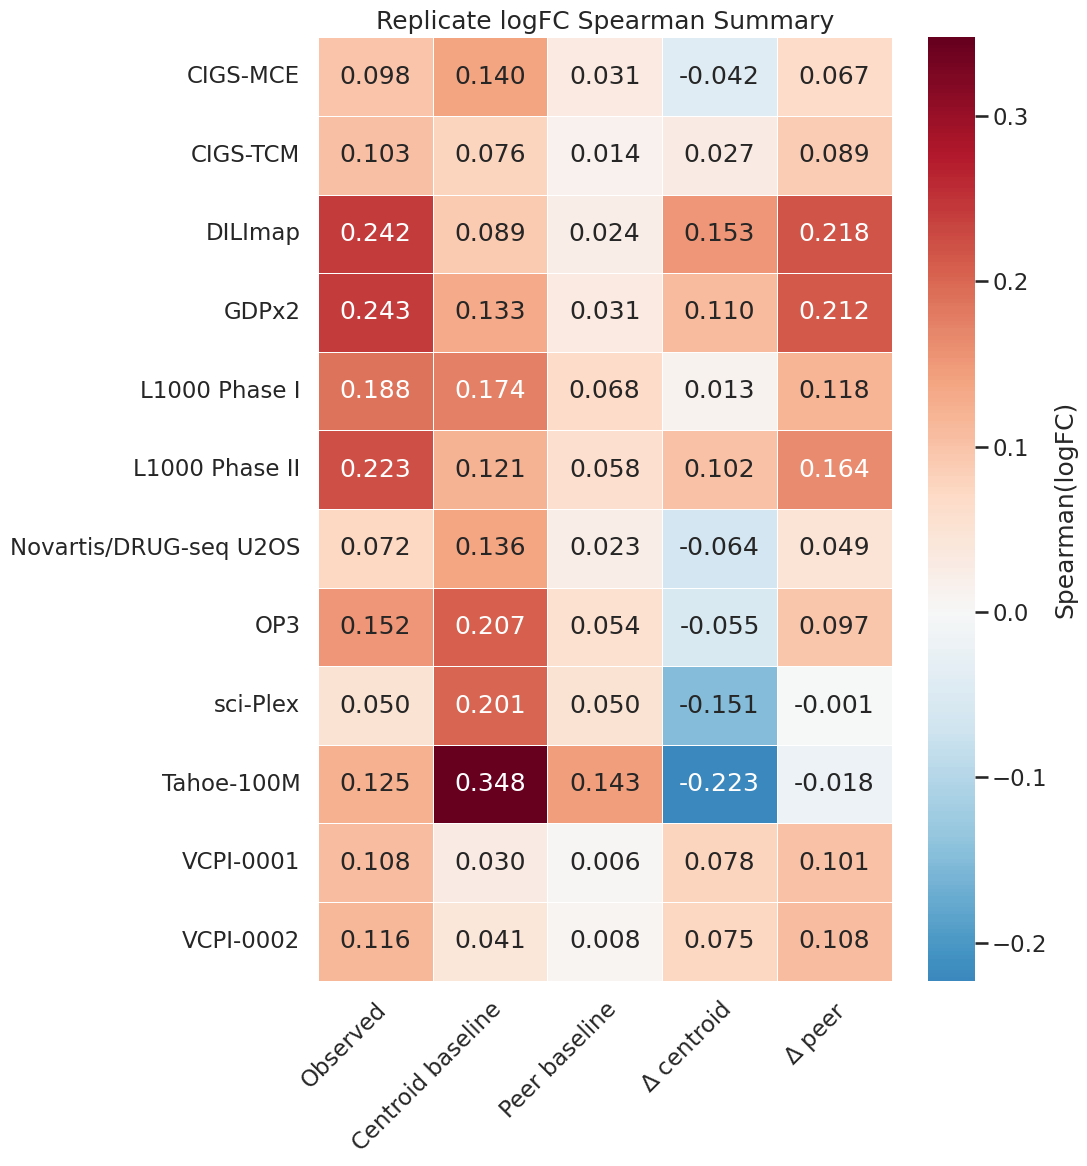

Saved heatmap to /ictstr01/home/icb/olga.novitskaia/Chem-PerturBridge_analysis_clean_up/results/replicate_signature_similarity_sep_rep/replicate_signature_logfc_heatmap.pdf


,Observed,Centroid baseline,Peer baseline,$\Delta$ centroid,$\Delta$ peer
Dataset,,,,,
CIGS-MCE,0.097999,0.139760,0.031314,-0.041761,0.066685
CIGS-TCM,0.102538,0.075854,0.014036,0.026684,0.088501
DILImap,0.242160,0.089059,0.023964,0.153157,0.218252
GDPx2,0.242817,0.132793,0.031076,0.110024,0.211741
L1000 Phase I,0.187725,0.174041,0.068406,0.012617,0.118252
L1000 Phase II,0.223118,0.120835,0.058429,0.101940,0.164347
Novartis/DRUG-seq U2OS,0.071825,0.136146,0.023313,-0.064321,0.048512
OP3,0.151550,0.206908,0.054051,-0.055358,0.097499
sci-Plex,0.049556,0.201016,0.050122,-0.151460,-0.000566


In [5]:
# Heatmap: signature logFC
signature_heatmap = plot_summary_heatmap(
    signature_summary,
    title='Replicate logFC Spearman Summary',
    value_label='Spearman(logFC)',
    pdf_name='replicate_signature_logfc_heatmap.pdf',
)